# MacBERT Fine-tuning for Comment Moderation

## Experiment E2
- Base Model: hfl/chinese-macbert-base
- Dataset: COLD
- Task: Binary Classification
- Labels: Safe (0), Offensive (1)
- Training: train.csv
- Validation: dev.csv
- Test: test.csv

In [103]:
import torch
import pandas as pd
import numpy as np

import transformers
import sklearn
from pathlib import Path
from transformers import (AutoTokenizer, AutoModelForSequenceClassification)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)


# 2. Device
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)



# 3. Model
MODEL_NAME = "hfl/chinese-macbert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer loaded successfully!'\n\n")


# 4. Load Classification Model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,  num_labels=2,      # num_labels=2：输出维度为 2，对应二分类
    # 这两个参数会被写进模型的 config，只是标签元数据（便于保存/展示时把 0/1 映射成 Safe/Offensive）。
    # 它不会改变 logits 的顺序，也不会自动把模型输出转成字符串
    id2label={0: "Safe",  1: "Offensive"},  label2id={"Safe": 0,  "Offensive": 1}
)

print("'\n\n'Model loaded successfully!")
print("Model parameters:",  sum(p.numel() for p in model.parameters()))

PyTorch: 2.15.0
Transformers: 5.23.0
Scikit-learn: 1.9.1
Device: mps
Tokenizer loaded successfully!'




Loading weights: 100%|██████████| 199/199 [00:00<00:00, 49315.60it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: hfl/chinese-macbert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archi

'

'Model loaded successfully!
Model parameters: 102269186


In [104]:
# 5. Load COLD Dataset
DATA_DIR = Path("../data/raw/COLDataset/COLDataset")
train_df = pd.read_csv(DATA_DIR / "train.csv", encoding="utf-8-sig",)
dev_df = pd.read_csv(DATA_DIR / "dev.csv", encoding="utf-8-sig",)

# 清理文本
for df in [train_df, dev_df]:
    df["TEXT"] = (df["TEXT"].fillna("").astype(str).str.strip())
    df["label"] = df["label"].astype(int)

# 检查数据
print("Train:", train_df.shape)
print("Dev:", dev_df.shape)

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nDev labels:")
print(dev_df["label"].value_counts())

assert set(train_df["label"].unique()) <= {0, 1}
assert set(dev_df["label"].unique()) <= {0, 1}

print("\nDataset loaded successfully!")

Train: (25726, 5)
Dev: (6431, 5)

Train labels:
label
0    13003
1    12723
Name: count, dtype: int64

Dev labels:
label
0    3220
1    3211
Name: count, dtype: int64

Dataset loaded successfully!


In [105]:
# 6. Analyze Token Length

def get_token_lengths(texts, batch_size=256):
    lengths = []

    for start in range(0, len(texts), batch_size):
        batch = texts.iloc[start:start + batch_size].tolist()
        encoded = tokenizer(batch, add_special_tokens=True, truncation=False, padding=False)

        lengths.extend([len(ids) for ids in encoded["input_ids"]])

    return np.array(lengths)


train_lengths = get_token_lengths(train_df["TEXT"])
dev_lengths = get_token_lengths(dev_df["TEXT"])


# 统计长度分布
print("Train Token Length")
print(pd.Series(train_lengths).describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

print("\nDev Token Length")
print(pd.Series(dev_lengths).describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

Train Token Length
count    25726.000000
mean        49.124038
std         30.347968
min          5.000000
50%         42.000000
75%         68.000000
90%         98.000000
95%        110.000000
99%        123.000000
max        193.000000
dtype: float64

Dev Token Length
count    6431.000000
mean       48.624475
std        30.463894
min         6.000000
50%        41.000000
75%        67.000000
90%        98.000000
95%       111.000000
99%       122.000000
max       192.000000
dtype: float64


In [106]:
# 7. Truncation Analysis   计算不同长度下的截断比例

limits = [128, 256, 384, 512]

for limit in limits:
    truncated = np.sum(train_lengths > limit)
    percentage = truncated / len(train_lengths) * 100

    print(f"Max Length {limit}: "
          f"{truncated} comments truncated "
          f"({percentage:.2f}%)")

Max Length 128: 64 comments truncated (0.25%)
Max Length 256: 0 comments truncated (0.00%)
Max Length 384: 0 comments truncated (0.00%)
Max Length 512: 0 comments truncated (0.00%)


In [107]:
# 8. Build PyTorch Dataset
from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 256

class CommentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(
            texts.tolist(), truncation=True,    # truncation=True：开启截断，超过`MAX_LENGTH`的句子会被截断
            max_length=MAX_LENGTH,  padding=False
        )
        self.labels = labels.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {}
        for key, value in self.encodings.items():
            item[key] = value[idx]

        item["labels"] = self.labels[idx]

        return item


# 创建 Dataset
train_dataset = CommentDataset(
    train_df["TEXT"], train_df["label"], tokenizer)

dev_dataset = CommentDataset(
    dev_df["TEXT"],  dev_df["label"],  tokenizer)

print("Train Dataset:", len(train_dataset))
print("Dev Dataset:", len(dev_dataset))

Train Dataset: 25726
Dev Dataset: 6431


In [108]:
# 9. Build DataLoader

BATCH_SIZE = 16
SEED = 42

def collate_fn(batch):
    # print("Batch 类型:", type(batch))
    # print("Batch 长度:", len(batch))
    # for idx, item in enumerate(batch):
    #     print(f"\n第 {idx + 1} 条评论:")
    #     print(item)

    # 1. 提取批次内所有标签，转为长整型张量
    labels = torch.tensor([item["labels"] for item in batch],  dtype=torch.long)

    # 2. 提取批次内所有样本的输入特征（移除labels字段）
    features = [{key: value  for key, value in item.items()  if key != "labels"} for item in batch]
    
    # 3. 按批次内最长句子做填充，返回PyTorch张量
    padded = tokenizer.pad(features, padding=True, return_tensors="pt")
    padded["labels"] = labels

    return padded


generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,   #shuffle=True：训练集打乱样本顺序，避免样本顺序影响模型训练，提升泛化能力；验证集不打乱，保证评估结果稳定可复现
    collate_fn=collate_fn,  # `collate_fn=collate_fn`：传入自定义的批次整理函数，实现动态填充
    num_workers=0, generator=generator # 提高模型复用性
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)


print("Train batches:", len(train_loader))
print("Dev batches:", len(dev_loader), '\n\n')


# 查看一个 Batch
sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    print(key, value.shape)

Train batches: 1608
Dev batches: 402 


input_ids torch.Size([16, 113])
token_type_ids torch.Size([16, 113])
attention_mask torch.Size([16, 113])
labels torch.Size([16])


In [109]:
# 10. Training Configuration

import random
from torch.optim import AdamW
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

# 将模型放到 MPS
model = model.to(device)

# Optimizer
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Learning Rate Scheduler
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * 0.1)  # Warmup：训练初期逐渐提高学习率，减少初期参数更新不稳定的问题


def lr_lambda(current_step):
    if current_step < warmup_steps:
        return current_step / max(1, warmup_steps)

    return max(0.0, (total_steps - current_step) / max(1, total_steps - warmup_steps))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

print("Training steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("Device:", device)

Training steps: 4824
Warmup steps: 482
Device: mps


In [110]:
# 11. Evaluation Function

def evaluate(model, dataloader):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch in dataloader:
            labels = batch["labels"]

            inputs = {key: value.to(device) for key, value in batch.items() if key != "labels"}
            outputs = model(**inputs)

            predictions = torch.argmax(outputs.logits, dim=-1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(all_labels, all_predictions, average="macro")
    offensive_precision = precision_score(all_labels, all_predictions, pos_label=1, zero_division=0)
    offensive_recall = recall_score(all_labels, all_predictions, pos_label=1, zero_division=0)

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "offensive_precision": offensive_precision,
        "offensive_recall": offensive_recall,
        "predictions": all_predictions,
        "labels": all_labels
    }

In [111]:
# 12. Fine-tuning MacBERT

from pathlib import Path
BEST_MODEL_DIR = (Path.cwd().parent / "models" / "macbert_cold_best")
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)
RUN_TRAINING = False  # False = 不训练，True = 重新训练


if RUN_TRAINING:

    best_macro_f1 = -1
    training_history = []

    for epoch in range(EPOCHS):
        print("\n" + "=" * 60)
        print(f"Epoch {epoch + 1}/{EPOCHS}")
        print("=" * 60)

        model.train()
        total_loss = 0

        for step, batch in enumerate(train_loader):
            labels = batch["labels"].to(device)  # 获取标签
            inputs = {key: value.to(device) for key, value in batch.items() if key != "labels"}  # 获取模型输入
            optimizer.zero_grad(set_to_none=True)    # 清空梯度

            outputs = model(**inputs, labels=labels)  # Forward
            loss = outputs.loss
            loss.backward()  # Backward

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Gradient Clipping

            optimizer.step()  # 更新参数
            scheduler.step()  # 更新学习率
            total_loss += loss.item()

            if (step + 1) % 200 == 0:
                print(f"Step [{step + 1}/{len(train_loader)}] " f"Loss: {loss.item():.4f}")

        avg_loss = total_loss / len(train_loader)
        metrics = evaluate(model, dev_loader)  # Validation

        print("\nTraining Loss:", round(avg_loss, 4))
        print("Validation Accuracy:", round(metrics["accuracy"], 4))
        print("Validation Macro F1:", round(metrics["macro_f1"], 4))
        print("Offensive Precision:", round(metrics["offensive_precision"], 4))
        print("Offensive Recall:", round(metrics["offensive_recall"], 4))

        training_history.append({
            "epoch": epoch + 1,
            "train_loss": avg_loss,
            "accuracy": metrics["accuracy"],
            "macro_f1": metrics["macro_f1"],
            "offensive_precision": metrics["offensive_precision"],
            "offensive_recall": metrics["offensive_recall"]
        })

        # 保存最佳模型
        if metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = metrics["macro_f1"]
            model.save_pretrained(str(BEST_MODEL_DIR))
            tokenizer.save_pretrained(str(BEST_MODEL_DIR))
            print("Best model saved!")

        print("\nBest Macro F1:", round(best_macro_f1, 4))
    print("\nTraining completed!")
else:
    print("Training skipped. Loading saved MacBERT...")

Training skipped. Loading saved MacBERT...


In [112]:
from pathlib import Path
from transformers import AutoConfig

BEST_MODEL_DIR = Path("../models/macbert_cold_best")
MODEL_NAME = "hfl/chinese-macbert-base"

# 从原始 MacBERT 加载正确的模型架构配置
config = AutoConfig.from_pretrained(MODEL_NAME)

# 恢复二分类配置
config.num_labels = 2
config.id2label = {0: "Safe", 1: "Offensive"}
config.label2id = {"Safe": 0, "Offensive": 1}

# 只修复 config.json，不修改 model.safetensors
config.save_pretrained(str(BEST_MODEL_DIR))

print("Model config restored!")
print("Model type:", config.model_type)

Model config restored!
Model type: bert


In [113]:
# Load Saved MacBERT

import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# 加载之前训练好的模型
tokenizer = AutoTokenizer.from_pretrained(str(BEST_MODEL_DIR))
model = AutoModelForSequenceClassification.from_pretrained(str(BEST_MODEL_DIR)).to(device)
model.eval()

print("Saved MacBERT loaded successfully!")
print("Device:", device)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10646.79it/s]


Saved MacBERT loaded successfully!
Device: mps


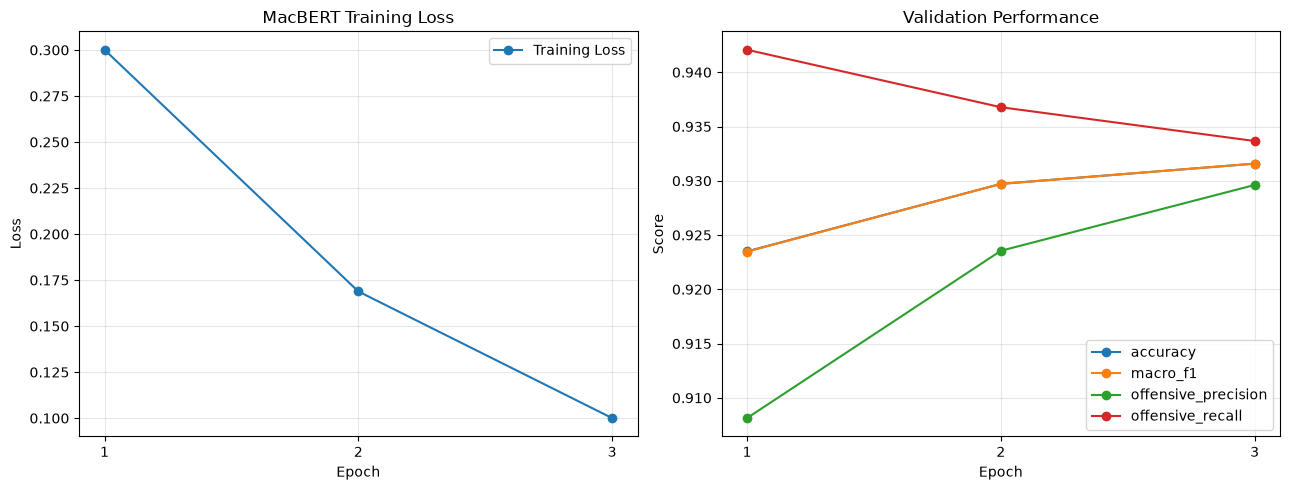

In [114]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(training_history)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training Loss
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training Loss")

axes[0].set_title("MacBERT Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks([1, 2, 3])
axes[0].grid(alpha=0.3)
axes[0].legend()

# Validation Metrics
for metric in ["accuracy", "macro_f1", "offensive_precision", "offensive_recall"]:
    axes[1].plot(history_df["epoch"], history_df[metric], marker="o", label=metric)

axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_xticks([1, 2, 3])
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 26161.52it/s]


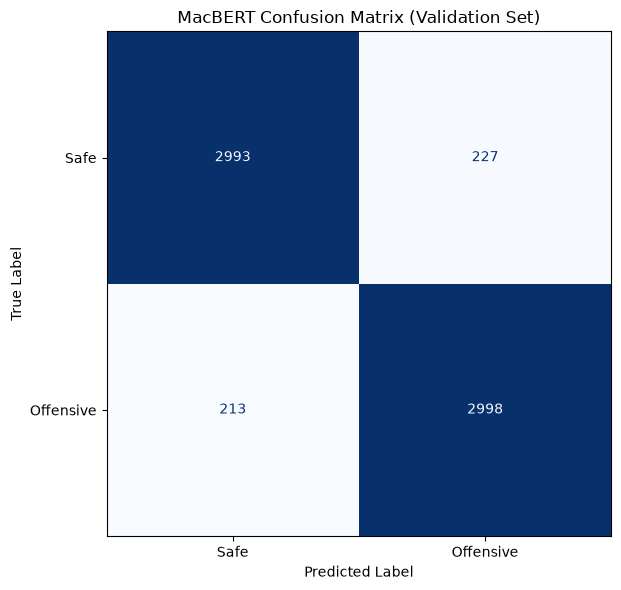

              precision    recall  f1-score   support

        Safe     0.9336    0.9295    0.9315      3220
   Offensive     0.9296    0.9337    0.9316      3211

    accuracy                         0.9316      6431
   macro avg     0.9316    0.9316    0.9316      6431
weighted avg     0.9316    0.9316    0.9316      6431



In [115]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from transformers import AutoModelForSequenceClassification  # 1. 加载之前保存的最佳模型

best_model = AutoModelForSequenceClassification.from_pretrained(str(BEST_MODEL_DIR)).to(device)

# 2. 在验证集上进行预测
metrics = evaluate(best_model, dev_loader)
y_true = metrics["labels"]
y_pred = metrics["predictions"]

# 3. 计算混淆矩阵
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# 4. 可视化
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Safe", "Offensive"])
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

plt.title("MacBERT Confusion Matrix (Validation Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 6. 输出分类报告
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=["Safe", "Offensive"], digits=4, zero_division=0))

In [116]:
# 14. Load Test Dataset

test_df = pd.read_csv(DATA_DIR / "test.csv", encoding="utf-8-sig")
test_df["TEXT"] = (test_df["TEXT"].fillna("").astype(str).str.strip())
test_df["label"] = test_df["label"].astype(int)

test_dataset = CommentDataset(test_df["TEXT"], test_df["label"], tokenizer)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=0)

print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

Test samples: 5323
Test batches: 333


In [117]:
# 15. Final Test Evaluation

best_model = AutoModelForSequenceClassification.from_pretrained(str(BEST_MODEL_DIR)).to(device)
test_metrics = evaluate(best_model, test_loader)

print("\nTEST RESULT")
print(classification_report(test_metrics["labels"], test_metrics["predictions"], target_names=["Safe", "Offensive"], digits=4))

cm = confusion_matrix(test_metrics["labels"], test_metrics["predictions"])
print("Confusion Matrix:")
print(cm)


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8376.44it/s]



TEST RESULT
              precision    recall  f1-score   support

        Safe     0.9005    0.7932    0.8434      3216
   Offensive     0.7329    0.8662    0.7940      2107

    accuracy                         0.8221      5323
   macro avg     0.8167    0.8297    0.8187      5323
weighted avg     0.8341    0.8221    0.8239      5323

Confusion Matrix:
[[2551  665]
 [ 282 1825]]


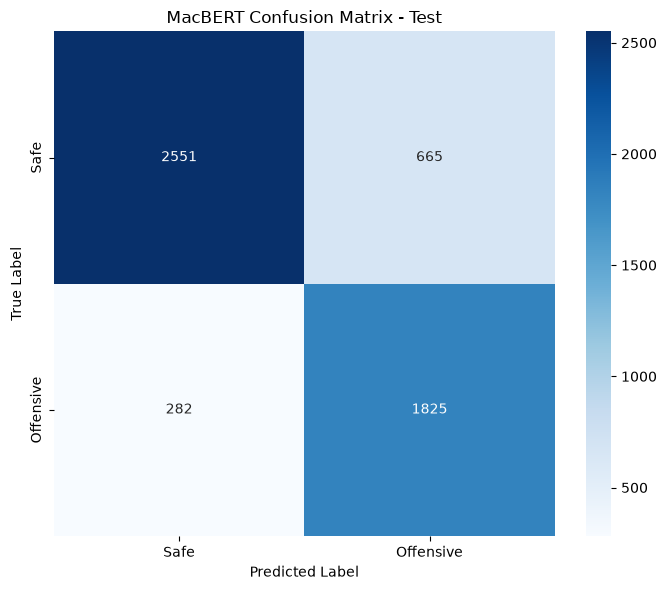

In [118]:
import seaborn as sns

plt.figure(figsize=(7, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Safe", "Offensive"], yticklabels=["Safe", "Offensive"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MacBERT Confusion Matrix - Test")
plt.tight_layout()
plt.show()

In [119]:
# Save Test Results

import json
from sklearn.metrics import classification_report
RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

report = classification_report(test_metrics["labels"],  test_metrics["predictions"], target_names=["Safe", "Offensive"], output_dict=True)
with open(RESULT_DIR / "macbert_test_classification_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=4)


# 保存混淆矩阵
cm = confusion_matrix(test_metrics["labels"], test_metrics["predictions"])

pd.DataFrame(cm, index=["True Safe", "True Offensive"], columns=["Pred Safe", "Pred Offensive"]).to_csv("../models/macbert_cold_best/macbert_test_confusion_matrix.csv")

# 保存预测结果，方便以后分析误分类
pd.DataFrame({"text": test_df["TEXT"], "true_label": test_metrics["labels"], "predicted_label": test_metrics["predictions"]}).to_csv(
    "../models/macbert_cold_best/macbert_test_predictions.csv", index=False, encoding="utf-8-sig"
)

print("Test results saved!")

Test results saved!


In [120]:
# 16. Save Test Predictions and Results

import json
import numpy as np
import pandas as pd

RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

best_model.eval()
all_probabilities = []

with torch.no_grad():
    for batch in test_loader:
        inputs = {
            key: value.to(device)
            for key, value in batch.items()
            if key != "labels"
        }

        outputs = best_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)[:, 1]
        all_probabilities.extend(probabilities.cpu().numpy())

all_probabilities = np.array(all_probabilities)
predictions = (all_probabilities >= 0.5).astype(int)

# 保存每条评论的预测结果
prediction_df = pd.DataFrame({
    "text": test_df["TEXT"],
    "true_label": test_df["label"],
    "predicted_label": predictions,
    "offensive_probability": all_probabilities
})

prediction_df["error_type"] = np.select(
    [(prediction_df["true_label"] == 0) & (prediction_df["predicted_label"] == 1), (prediction_df["true_label"] == 1) & (prediction_df["predicted_label"] == 0)],
    ["False Positive", "False Negative"],
    default="Correct"
)

prediction_df.to_csv(RESULT_DIR / "macbert_test_predictions.csv", index=False, encoding="utf-8-sig")

print("Test predictions saved!")
print(prediction_df["error_type"].value_counts())

Test predictions saved!
error_type
Correct           4376
False Positive     665
False Negative     282
Name: count, dtype: int64


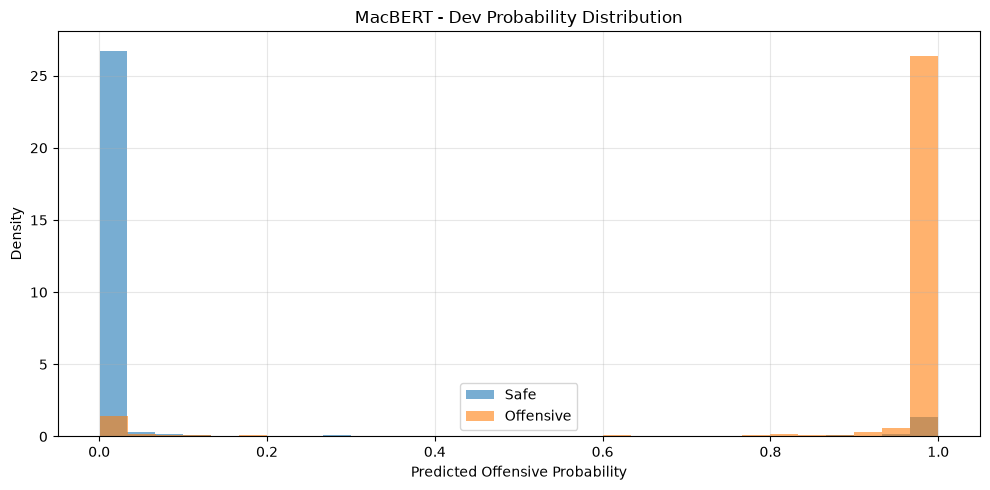

In [121]:
# Dev Probability Analysis
RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

best_model.eval()
dev_probabilities = []
dev_labels = []

with torch.no_grad():
    for batch in dev_loader:
        inputs = {
            key: value.to(device)
            for key, value in batch.items()
            if key != "labels"
        }

        outputs = best_model(**inputs)

        probabilities = torch.softmax(outputs.logits, dim=-1)[:, 1]
        dev_probabilities.extend(probabilities.cpu().numpy())
        dev_labels.extend(batch["labels"].numpy())

dev_prob = np.array(dev_probabilities)
dev_true = np.array(dev_labels)

# 保存 Dev 预测概率
dev_prediction_df = pd.DataFrame({
    "text": dev_df["TEXT"].reset_index(drop=True), "true_label": dev_true, "offensive_probability": dev_prob})

dev_prediction_df.to_csv(RESULT_DIR / "macbert_dev_probabilities.csv", index=False, encoding="utf-8-sig")

# 绘制概率分布
plt.figure(figsize=(10, 5))
plt.hist(dev_prob[dev_true == 0], bins=30, alpha=0.6, density=True, label="Safe")
plt.hist(dev_prob[dev_true == 1], bins=30, alpha=0.6, density=True, label="Offensive")
plt.xlabel("Predicted Offensive Probability")
plt.ylabel("Density")
plt.title("MacBERT - Dev Probability Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [122]:
# Threshold Search - MacBERT

thresholds = np.arange(0.01, 1.00, 0.01)
MIN_AUTO_SAMPLES = 50
results = []

for allow_threshold in thresholds:
    for block_threshold in thresholds:
        if allow_threshold >= block_threshold:
            continue

        allow_mask = dev_prob <= allow_threshold   # 自动放行
        block_mask = dev_prob >= block_threshold    # 自动拦截

        allow_count = allow_mask.sum()
        block_count = block_mask.sum()

        # 排除样本量太少的组合
        if allow_count < MIN_AUTO_SAMPLES:
            continue

        if block_count < MIN_AUTO_SAMPLES:
            continue

        allow_precision = np.mean(dev_true[allow_mask] == 0)  # 自动放行区域的 Safe Precision
        block_precision = np.mean(dev_true[block_mask] == 1)  # 自动拦截区域的 Offensive Precision
        llm_count = (len(dev_true) - allow_count - block_count)
        auto_coverage = (allow_count + block_count) / len(dev_true)

        results.append({
            "Allow Threshold": allow_threshold,
            "Block Threshold": block_threshold,
            "Allow Precision": allow_precision,
            "Block Precision": block_precision,
            "Auto Allow": allow_count,
            "Auto Block": block_count,
            "LLM Review": llm_count,
            "Auto Coverage": auto_coverage,
            "LLM Rate": llm_count / len(dev_true)
        })

threshold_df = pd.DataFrame(results)


# Compare Different Precision Targets
for target in [0.90, 0.95, 0.97, 0.99]:
    qualified = threshold_df[(threshold_df["Allow Precision"] >= target) & (threshold_df["Block Precision"] >= target)]

    print("\n" + "=" * 60)
    print(f"PRECISION TARGET: {target:.0%}")
    print("=" * 60)

    if qualified.empty:
        print("No qualifying threshold combination.")
        continue

    best = qualified.sort_values("Auto Coverage", ascending=False).iloc[0]
    print("Allow Threshold:", round(best["Allow Threshold"], 2))
    print("Block Threshold:", round(best["Block Threshold"], 2))
    print("Allow Precision:", round(best["Allow Precision"], 4))     # 所有被自动放行的评论中，真正属于 Safe 的比例
    print("Block Precision:", round(best["Block Precision"], 4))     # 所有被自动放行的评论中，真正属于 Safe 的比例
    print("Auto Coverage:", f'{best["Auto Coverage"]:.2%}')
    print("LLM Review Rate:",  f'{best["LLM Rate"]:.2%}')
    print("Auto Allow:", int(best["Auto Allow"]))
    print("Auto Block:", int(best["Auto Block"]))
    print("LLM Review:", int(best["LLM Review"]))

# 保存全部阈值组合
threshold_df.to_csv(RESULT_DIR / "macbert_dev_threshold_search.csv", index=False)
print("\nThreshold search completed!")

# eg:
# 𝑃 ≤ 0.26 P≤0.26：自动放行。 
# 𝑃 ≥ 0.27 P≥0.27：自动拦截。 
# 0.26 < 𝑃 < 0.27 0.26<P<0.27：交给 LLM。



PRECISION TARGET: 90%
Allow Threshold: 0.26
Block Threshold: 0.27
Allow Precision: 0.9367
Block Precision: 0.92
Auto Coverage: 100.00%
LLM Review Rate: 0.00%
Auto Allow: 3158
Auto Block: 3273
LLM Review: 0

PRECISION TARGET: 95%
Allow Threshold: 0.04
Block Threshold: 0.96
Allow Precision: 0.9501
Block Precision: 0.9502
Auto Coverage: 93.55%
LLM Review Rate: 6.45%
Auto Allow: 3027
Auto Block: 2989
LLM Review: 415

PRECISION TARGET: 97%
No qualifying threshold combination.

PRECISION TARGET: 99%
No qualifying threshold combination.

Threshold search completed!


Loaded: ../results/macbert_dev_probabilities.csv
Samples: 6431

BRIER SCORE
MacBERT Brier Score(Brier Score 越低越好,0 是完美预测): 0.06237
Reference Brier Score: 0.25
Brier Skill Score: 0.75051

Log Loss: 0.29376

CALIBRATION METRICS
ECE: 0.05507
MCE: 0.31842

Calibration Table:


,Bin,Count,Mean Predicted Probability,Actual Offensive Rate,Calibration Gap
0,0.0-0.1,3096,0.0040,0.0562,0.0522
1,0.1-0.2,50,0.1416,0.4600,0.3184
2,0.2-0.3,26,0.2579,0.2692,0.0114
3,0.3-0.4,18,0.3539,0.2778,0.0761
4,0.4-0.5,16,0.4536,0.2500,0.2036
5,0.5-0.6,20,0.5605,0.5000,0.0605
6,0.6-0.7,34,0.6449,0.5882,0.0566
7,0.7-0.8,31,0.7550,0.5806,0.1743
8,0.8-0.9,61,0.8521,0.6721,0.1800
9,0.9-1.0,3079,0.9942,0.9448,0.0494


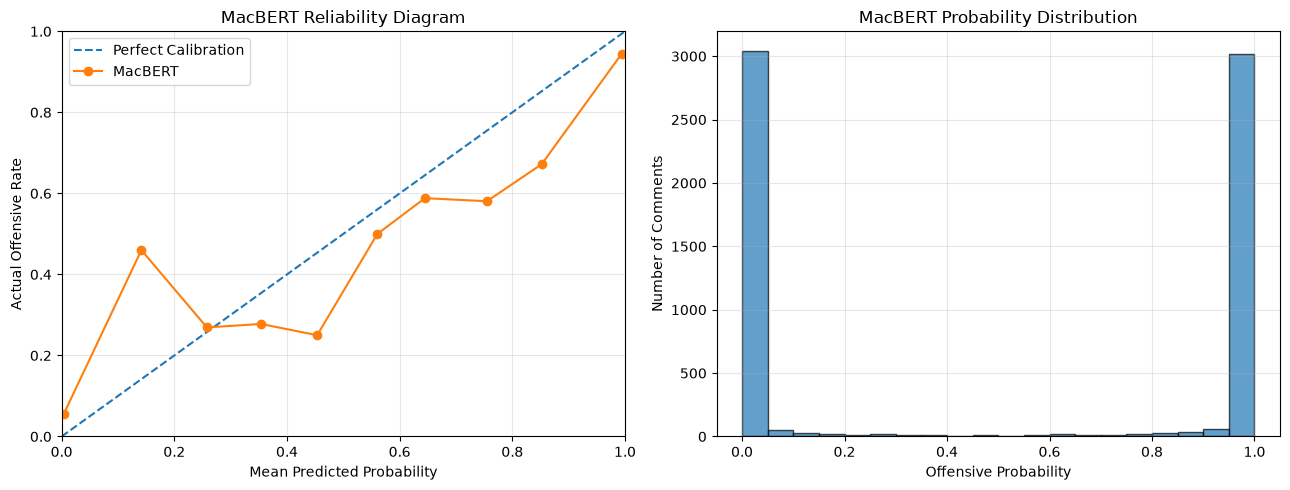


Calibration analysis completed!


In [ ]:
# Calibration Analysis - MacBERT

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import brier_score_loss, log_loss


# 1. Load Saved Dev Predictions
possible_paths = [
    Path("../results/macbert_dev_probabilities.csv"),
    Path("results/macbert_dev_probabilities.csv"),
    Path.cwd().parent / "results" / "macbert_dev_probabilities.csv"
]

DEV_PROB_PATH = next((p for p in possible_paths if p.exists()), None)
if DEV_PROB_PATH is None:
    raise FileNotFoundError("macbert_dev_probabilities.csv not found!")
df = pd.read_csv(DEV_PROB_PATH)

y_true = df["true_label"].to_numpy(dtype=int)
y_prob = df["offensive_probability"].to_numpy(dtype=float)
assert len(y_true) == len(y_prob)
assert set(np.unique(y_true)).issubset({0, 1})
assert np.isfinite(y_prob).all()
assert np.all((y_prob >= 0) & (y_prob <= 1))
print("Loaded:", DEV_PROB_PATH)
print("Samples:", len(y_true))



# 2. Brier Score
brier = brier_score_loss(y_true, y_prob)
# Reference: always predict the Dev positive-class rate
base_rate = y_true.mean()
reference_brier = np.mean((y_true - base_rate) ** 2)
brier_skill_score = (1 - brier / reference_brier)

print("\n" + "=" * 55)
print("BRIER SCORE")
print("=" * 55)
print("MacBERT Brier Score(Brier Score 越低越好,0 是完美预测):", round(brier, 5))
print("Reference Brier Score:", round(reference_brier, 5))
print("Brier Skill Score:", round(brier_skill_score, 5))


# 3. Log Loss
logloss = log_loss(y_true, y_prob, labels=[0, 1])
print("\nLog Loss:", round(logloss, 5))


# 4. Expected Calibration Error (ECE)
N_BINS = 10
bin_edges = np.linspace(0, 1, N_BINS + 1)
bin_indices = np.digitize(y_prob, bin_edges[1:-1], right=False)
calibration_results = []
ece = 0.0
for i in range(N_BINS):
    mask = bin_indices == i
    count = mask.sum()
    if count == 0:
        continue

    mean_predicted = y_prob[mask].mean()
    actual_positive_rate = y_true[mask].mean()
    gap = abs(mean_predicted - actual_positive_rate)
    ece += (count / len(y_true)) * gap
    calibration_results.append({
        "Bin": f"{bin_edges[i]:.1f}-{bin_edges[i+1]:.1f}",
        "Count": count,
        "Mean Predicted Probability": mean_predicted,   # 该区间内模型预测概率的平均值
        "Actual Offensive Rate": actual_positive_rate,  # 该区间内真实 Offensive 的比例
        "Calibration Gap": gap      # 预测概率与真实比例的差距
    })


calibration_df = pd.DataFrame(calibration_results)
mce = calibration_df["Calibration Gap"].max()

print("\n" + "=" * 55)
print("CALIBRATION METRICS")
print("=" * 55)
print("ECE:", round(ece, 5))
print("MCE:", round(mce, 5))
print("\nCalibration Table:")
display(calibration_df.round(4))


# 5. Save Results
RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)
calibration_df.to_csv(RESULT_DIR / "macbert_dev_calibration_bins.csv", index=False)


# 6. Reliability Diagram
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Reliability Diagram
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
axes[0].plot(calibration_df["Mean Predicted Probability"], calibration_df["Actual Offensive Rate"], marker="o", label="MacBERT")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Actual Offensive Rate")
axes[0].set_title("MacBERT Reliability Diagram")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.3)
axes[0].legend()

# Right: Probability Histogram
axes[1].hist(y_prob, bins=20, edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Offensive Probability")
axes[1].set_ylabel("Number of Comments")
axes[1].set_title("MacBERT Probability Distribution")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
print("\nCalibration analysis completed!")

# eg:
# 第一步：找出模型预测 Offensive 概率在 0～10% 的评论。 一共有 3096 条。 
# 第二步：这些评论的平均预测概率是：0.0040=0.4% 也就是说，MacBERT 极其确信这些评论是 Safe。 
# 第三步：检查真实标签。 实际 Offensive 比例为：0.0562=5.62% 这意味着模型认为它们只有 0.4% 的可能性是有害评论，但实际上有 5.62% 是有害评论。模型低估了这部分评论的有害概率。 
# 第四步：计算差距： 𝐺𝑎𝑝 = ∣0.0040−0.0562∣ = ∣0.0040−0.0562∣ 也就是 5.22 个百分点。 这就是 Calibration Gap。
